<a href="https://colab.research.google.com/github/alessiomodonesi/Python-Exercises/blob/main/AI_MSc/lab2/Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2

This notebook has two parts:
- **Part 1 — Search algorithms**: uninformed search, informed search and local search;
- **Part 2 — Adversarial search**: Tic-Tac-Toe with Minimax and Monte Carlo Tree Search.


# Search Algorithms

**Contents**
1. Problem and node
2. The map of Romania
3. Uninformed search (BFS, DFS, uniform cost)
4. Informed search (greedy, A\*)
5. Local search (hill climbing, simulated annealing)


In [44]:
# Standard libraries + matplotlib and networkx
import math, random, heapq, time
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx

random.seed(42)

## 1. Problem and node

A **search problem** is defined by:
- an **initial state**;
- the **actions** available in each state;
- the **transition model** `result(state, action)`;
- the **goal test**;
- the **cost** of each step.

A **node** of the search tree contains a state, the parent node, the action that generated it and the path cost `g(n)` from the root.

In [45]:
class Problem:
    "Abstract class: subclasses override actions, result and (if needed) h."
    def __init__(self, initial, goal=None):
        self.initial, self.goal = initial, goal

    def actions(self, state):            raise NotImplementedError
    def result(self, state, action):     raise NotImplementedError
    def goal_test(self, state):          return state == self.goal
    def path_cost(self, c, s1, a, s2):   return c + 1          # unit step cost by default
    def h(self, node):                   return 0              # heuristic (0 = no information)


class Node:
    def __init__(self, state, parent=None, action=None, path_cost=0):
        self.state, self.parent, self.action, self.path_cost = state, parent, action, path_cost
        self.depth = parent.depth + 1 if parent else 0

    def expand(self, problem):
        "Return the child nodes."
        return [self.child(problem, a) for a in problem.actions(self.state)]

    def child(self, problem, action):
        s2 = problem.result(self.state, action)
        return Node(s2, self, action, problem.path_cost(self.path_cost, self.state, action, s2))

    def path(self):
        "List of nodes from the root to this node."
        node, out = self, []
        while node:
            out.append(node)
            node = node.parent
        return out[::-1]

    def solution(self):
        "Sequence of actions from the root to this node."
        return [n.action for n in self.path()[1:]]

    def __lt__(self, other):   # needed by heapq to break ties
        return self.state < other.state

    def __repr__(self):
        return f"<Node {self.state}>"

## 2. The map of Romania

The classic problem from the book: going from **Arad** to **Bucharest**. The graph is undirected; each edge is weighted by the road distance. The coordinates are used to draw the map and for the heuristic (straight-line distance).

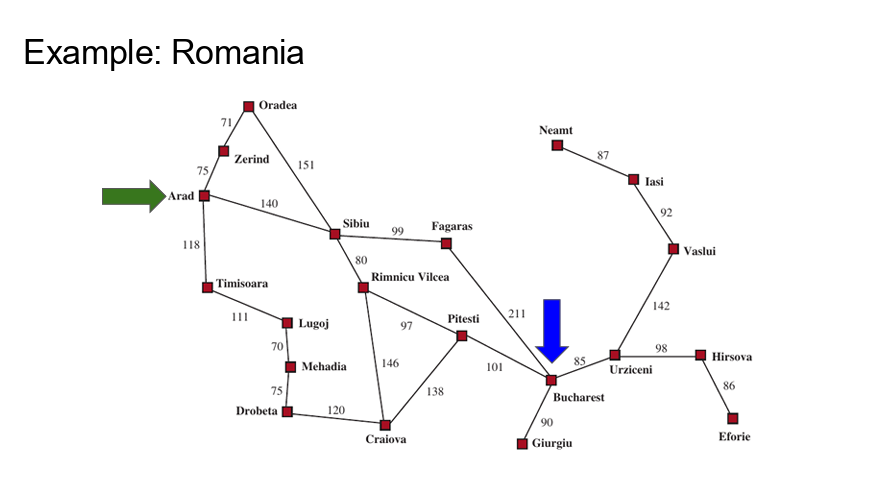

In [46]:
roads = dict(
    Arad=dict(Zerind=75, Sibiu=140, Timisoara=118),
    Bucharest=dict(Urziceni=85, Pitesti=101, Giurgiu=90, Fagaras=211),
    Craiova=dict(Drobeta=120, Rimnicu=146, Pitesti=138),
    Drobeta=dict(Mehadia=75),
    Eforie=dict(Hirsova=86),
    Fagaras=dict(Sibiu=99),
    Hirsova=dict(Urziceni=98),
    Iasi=dict(Vaslui=92, Neamt=87),
    Lugoj=dict(Timisoara=111, Mehadia=70),
    Oradea=dict(Zerind=71, Sibiu=151),
    Pitesti=dict(Rimnicu=97),
    Rimnicu=dict(Sibiu=80),
    Urziceni=dict(Vaslui=142))

# undirected, weighted networkx graph
romania = nx.Graph()
for a, nbrs in roads.items():
    for b, d in nbrs.items():
        romania.add_edge(a, b, weight=d) # Create nodes a and b if they don't exist yet, and add an edge between them with weight d

locations = dict(
    Arad=(91, 492), Bucharest=(400, 327), Craiova=(253, 288),
    Drobeta=(165, 299), Eforie=(562, 293), Fagaras=(305, 449),
    Giurgiu=(375, 270), Hirsova=(534, 350), Iasi=(473, 506),
    Lugoj=(165, 379), Mehadia=(168, 339), Neamt=(406, 537),
    Oradea=(131, 571), Pitesti=(320, 368), Rimnicu=(233, 410),
    Sibiu=(207, 457), Timisoara=(94, 410), Urziceni=(456, 350),
    Vaslui=(509, 444), Zerind=(108, 531))

nx.set_node_attributes(romania, locations, "pos")   # position stored as a node attribute

print(romania.number_of_nodes(), "cities,", romania.number_of_edges(), "roads")
print("Neighbors of Arad:", {v: romania["Arad"][v]["weight"] for v in romania.neighbors("Arad")})

20 cities, 23 roads
Neighbors of Arad: {'Zerind': 75, 'Sibiu': 140, 'Timisoara': 118}


In [47]:
class GraphProblem(Problem):
    "Find a path between two nodes of a weighted networkx graph ('weight' attribute)."
    def __init__(self, initial, goal, graph):
        super().__init__(initial, goal)
        self.graph = graph

    def actions(self, state):          return list(self.graph.neighbors(state))   # action = city to move to
    def result(self, state, action):   return action
    def path_cost(self, c, s1, a, s2): return c + self.graph[s1][s2]["weight"]

    def h(self, node):
        "Straight-line distance to the goal (from the 'pos' attributes)."
        pos = nx.get_node_attributes(self.graph, "pos")
        if not pos:
            return 0
        (x1, y1), (x2, y2) = pos[node.state], pos[self.goal]
        return math.hypot(x1 - x2, y1 - y2)

romania_problem = GraphProblem("Arad", "Bucharest", romania)

Drawing with `networkx`: **orange** = explored nodes, **green** = path found.

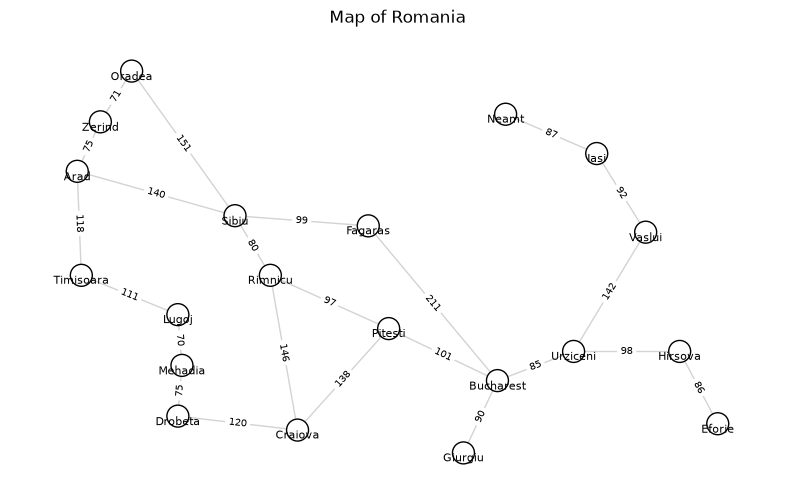

In [48]:
def draw_map(explored=(), path=(), title="Map of Romania", G=romania):
    pos = nx.get_node_attributes(G, "pos")
    path_edges = list(zip(path, path[1:]))
    colors = ["limegreen" if v in path else "orange" if v in explored else "white" for v in G.nodes]

    plt.figure(figsize=(10, 6))
    nx.draw_networkx_edges(G, pos, edge_color="lightgray")
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="green", width=3)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=7)
    nx.draw_networkx_nodes(G, pos, node_color=colors, edgecolors="black", node_size=250)
    nx.draw_networkx_labels(G, pos, labels={v: v for v in G}, font_size=8,
                            verticalalignment="top", horizontalalignment="center")
    plt.title(title); plt.axis("off"); plt.show()

draw_map()

## 3. Uninformed search

All the following algorithms return `(solution_node, explored_set)`, so we can compare and draw them.

| Algorithm | Frontier | Complete | Optimal |
|---|---|---|---|
| Breadth-first (BFS) | FIFO queue | yes | yes, if step costs are equal |
| Depth-first (DFS) | LIFO stack | no (in general) | no |
| Uniform cost (UCS) | priority queue on `g(n)` | yes | yes |

### Exercise 1: Implement BFS and DFS

Complete the two functions in the cell below. Each one must return a pair `(solution_node, visited)`:
- `solution_node` is the `Node` that contains the goal state (or `None` if there is no solution);
- `visited` is the set of states already seen during the search.

**Steps**
0. Delete the `raise NotImplementedError(...)` line at the top of the function.
1. Create the frontier containing only the root node `Node(problem.initial)`.
2. Create the set `visited` containing the initial state.
3. While the frontier is not empty:
   - take a node out of the frontier;
   - if it is the goal (`problem.goal_test(node.state)`), return it together with `visited`;
   - otherwise, for each child in `node.expand(problem)`: if its state has not been seen yet, add the state to `visited` and the child to the frontier.
4. If the frontier becomes empty, return `None, visited`.

**Hints**
- The only difference between BFS and DFS is **which node you take out** of the frontier.
- BFS uses a **FIFO queue**: `deque([...])`, add with `append()`, remove with `popleft()` (the oldest node).
- DFS uses a **LIFO stack**: a plain list, add with `append()`, remove with `pop()` (the newest node).
- Mark a state as visited **when you add it to the frontier**, not when you take it out: this way the same state is never added twice.

When you are done, test your code with `report("Breadth-first", breadth_first_search, romania_problem)` after running the cell with the `report` function below. BFS should find `Arad → Sibiu → Fagaras → Bucharest`.

In [49]:
def breadth_first_search(problem):
    # raise NotImplementedError("Complete breadth_first_search") # TODO: delete this line
    frontier = deque([Node(problem.initial)]) # TODO: FIFO queue containing the root node
    visited = {problem.initial} # TODO: set containing the initial state
    while frontier:
        node = frontier.popleft() # TODO: take the OLDEST node
        # TODO: if node is the goal, return node, visited
        if problem.goal_test(node.state): return node, visited
        else:
        # TODO: for each child of node, if its state is not in visited,
        #       add the state to visited and the child to the frontier
            for n in node.expand(problem):
                if n.state not in visited:
                    visited.add(n.state)
                    frontier.append(n)
    return None, visited


def depth_first_search(problem):
    # raise NotImplementedError("Complete depth_first_search") # TODO: delete this line
    frontier = [Node(problem.initial)] # TODO: LIFO stack (a list) containing the root node
    visited  = {problem.initial} # TODO: set containing the initial state
    while frontier:
        node = frontier.pop() # TODO: take the NEWEST node
        # TODO: same steps as in BFS
        if problem.goal_test(node.state): return node, visited
        else:
            for n in node.expand(problem):
                if n.state not in visited:
                    visited.add(n.state)
                    frontier.append(n)
    return None, visited

### Exercise 2: Implement best-first search and uniform cost search

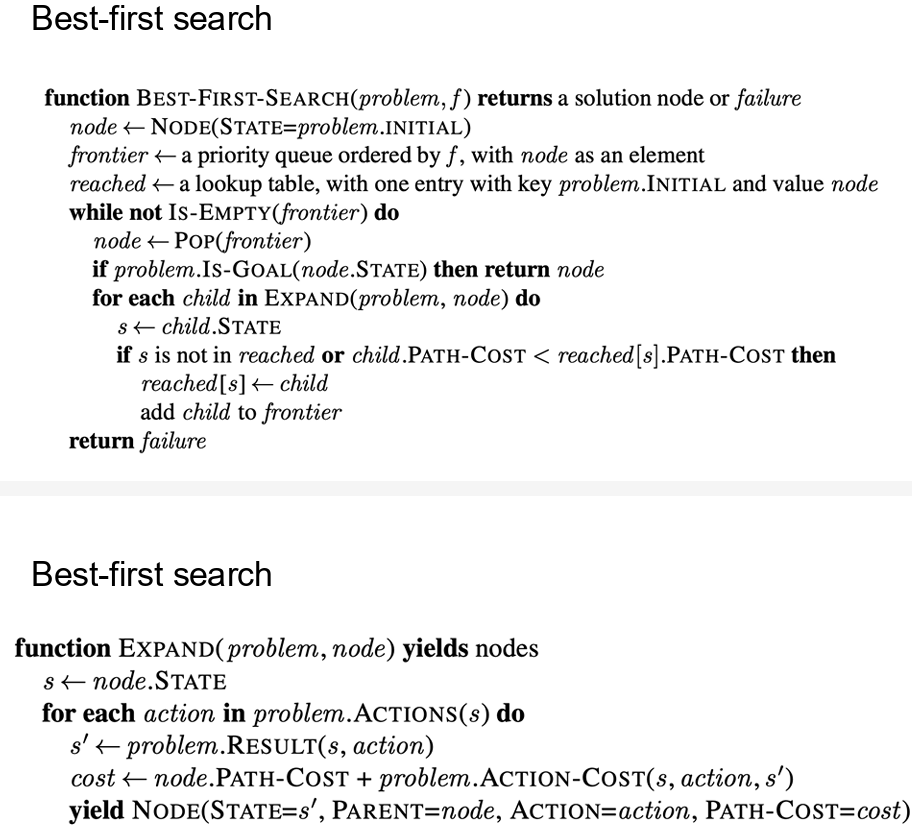

**Best-first search** always expands the node with the **lowest value of an evaluation function `f(n)`**. Changing `f` gives different algorithms:
- `f(n) = g(n)` (the path cost) → **uniform cost search**;
- `f(n) = h(n)` → greedy best-first;
- `f(n) = g(n) + h(n)` → A\*.

Complete the two functions in the cell below. `best_first_search` must return a pair `(solution_node, explored)`:
- `solution_node` is the `Node` that contains the goal state (or `None` if there is no solution);
- `explored` is the set of states already **expanded**.

**Steps**
0. Delete the `raise NotImplementedError(...)` line at the top of the function.
1. Create the root node `Node(problem.initial)` and a frontier containing the pair `(f(root), root)`.
2. Create an empty set `explored`.
3. While the frontier is not empty:
   - take out the pair with the lowest `f`;
   - if its state is already in `explored`, skip it (`continue`);
   - if it is the goal, return it together with `explored`;
   - otherwise add its state to `explored` and, for each child whose state is not in `explored`, add `(f(child), child)` to the frontier.
4. If the frontier becomes empty, return `None, explored`.

Then write `uniform_cost_search` in **one line**, by calling `best_first_search` with the right `f`.

**Hints**
- The frontier is a **priority queue**: use a plain list with `heapq.heappush(frontier, (priority, node))` to add and `heapq.heappop(frontier)` to take out the pair with the **lowest** priority.
- `heappop` returns the whole pair: unpack it with `f_value, node = heapq.heappop(frontier)`.
- `f` is a function: call it as `f(node)`. Use `lambda n: ...` to write it in one line; the path cost of a node is `n.path_cost`.
- The same state may enter the frontier more than once with different costs. The cheapest copy comes out first; the others are skipped because their state is already in `explored`.
- Unlike BFS, the goal test is done when the node is **taken out** of the frontier: otherwise the path found might not be the cheapest.

When you are done, test your code with `report("Uniform cost", uniform_cost_search, romania_problem)` after running the cell with the `report` function below. It should find `Arad → Sibiu → Rimnicu → Pitesti → Bucharest` with cost 418.

In [50]:
def best_first_search(problem, f):
    # raise NotImplementedError("Complete best_first_search") # TODO: delete this line
    root = Node(problem.initial) # TODO: root node
    frontier = [(f(root), root)] # TODO: list containing the pair (f(root), root)
    explored = set() # TODO: empty set
    while frontier:
        f_value, node = heapq.heappop(frontier) # TODO: take out the pair with the LOWEST f
        # TODO: if node.state is already in explored, skip it
        if node.state in explored: continue
        # TODO: if node is the goal, return node, explored
        if problem.goal_test(node.state): return node, explored
        # TODO: add node.state to explored
        explored.add(node.state)
        # TODO: for each child whose state is not in explored,
        #       push (f(child), child) into the frontier
        for n in node.expand(problem):
            if n.state not in explored:
                heapq.heappush(frontier, (f(n), n))
    return None, explored


def uniform_cost_search(problem):
    return best_first_search(problem, lambda n: n.path_cost)   # f(n) = g(n), the path cost

Let's try the four algorithms on Arad → Bucharest and compare **path**, **cost** and **number of explored nodes**.

In [51]:
def report(name, algorithm, problem):
    node, explored = algorithm(problem)
    path = [n.state for n in node.path()]
    print(f"{name:<28} cost={node.path_cost:>4.0f}  explored={len(explored):>2}  {' → '.join(path)}")
    return node, explored

for name, alg in [("Breadth-first", breadth_first_search),
                  ("Depth-first", depth_first_search),
                  ("Uniform cost", uniform_cost_search)]:
    report(name, alg, romania_problem)

Breadth-first                cost= 450  explored=12  Arad → Sibiu → Fagaras → Bucharest
Depth-first                  cost= 733  explored=11  Arad → Timisoara → Lugoj → Mehadia → Drobeta → Craiova → Pitesti → Bucharest
Uniform cost                 cost= 418  explored=12  Arad → Sibiu → Rimnicu → Pitesti → Bucharest


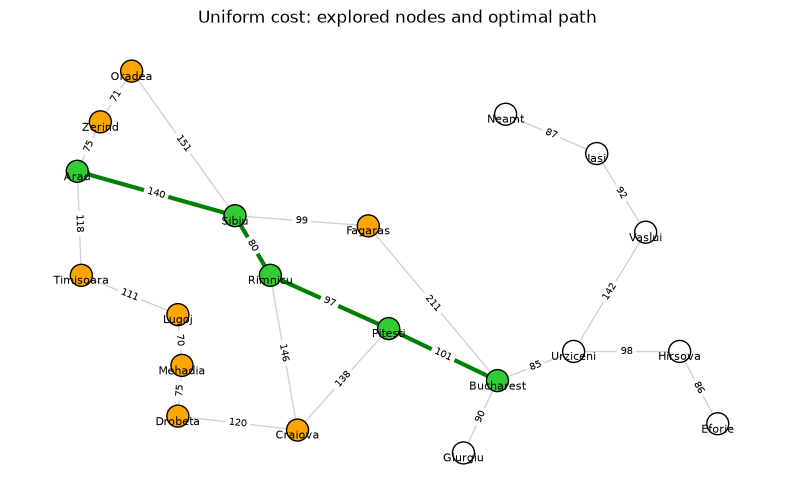

In [52]:
node, explored = uniform_cost_search(romania_problem)
draw_map(explored, [n.state for n in node.path()], "Uniform cost: explored nodes and optimal path")

## 4. Informed search

We use a **heuristic** `h(n)` = straight-line distance from `n` to Bucharest.

- **Greedy best-first**: `f(n) = h(n)` — fast but not optimal.
- **A\***: `f(n) = g(n) + h(n)` — optimal if `h` is admissible (never overestimates)

> **Note:** greedy best-first and A\* reuse the same `best_first_search` written for uniform cost search: the implementation never changes, only the lambda function passed as `f` does.
> - uniform cost: `lambda n: n.path_cost`
> - greedy: `lambda n: h(n)`
> - A\*: `lambda n: n.path_cost + h(n)`

In [ ]:
def greedy_best_first_search(problem, h=None):
    h = h or problem.h
    return best_first_search(problem, lambda n: h(n))


def astar_search(problem, h=None):
    h = h or problem.h
    return best_first_search(problem, lambda n: n.path_cost + h(n))


In [ ]:
for name, alg in [("Greedy best-first", greedy_best_first_search),
                  ("A*", astar_search)]:
    report(name, alg, romania_problem)

node, explored = astar_search(romania_problem)
draw_map(explored, [n.state for n in node.path()], "A*: explores fewer nodes than uniform cost, same optimal path")

Note: **greedy** finds a path (via Fagaras) that is more expensive than the optimal one (via Rimnicu and Pitesti, cost 418), while **A\*** finds the optimal one exploring fewer nodes than uniform cost.

## 5. Local search

When only the **final state** matters (not the path), we can move between complete states, improving them step by step.

We use the **N-queens** problem: the state is a tuple where `state[c]` is the row of the queen in column `c`; we want **0 conflicting pairs**.


### **N-queens** problem

Put n queens on an n x n board with no two queens on
the same row, column, or diagonal:
*   Each state has n queens on the board, one per column
*   Successors of a state: all possible states generated by moving
*   A single queen to another square in the same column

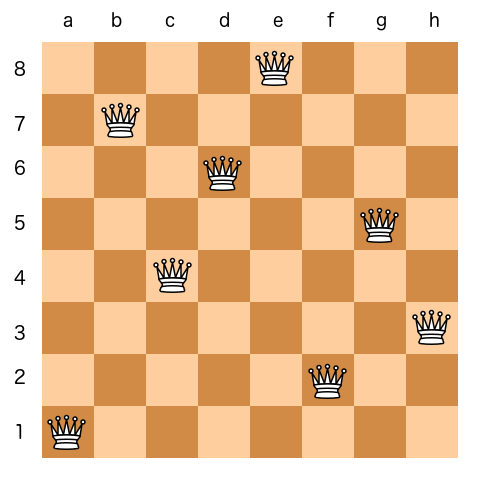


### Problem definition

To find the possible arrangements of 8 queens on a standard 8x8 chessboard so that no queen is in an offensive position. If we know the basics of chess, we can say that a queen can move horizontally, vertically, or diagonally. Therefore, for two or more queens to be on the offensive, they must be horizontally, vertically, or transversely aligned with the other queen. The figure below shows an example of the queen's attack situations.


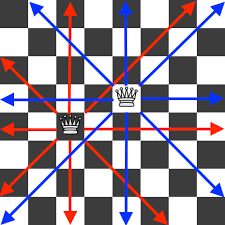

In [ ]:
def conflicts(state):
    "Number of pairs of queens attacking each other."
    n = len(state)
    return sum(1 for i in range(n) for j in range(i + 1, n)
               if state[i] == state[j] or abs(state[i] - state[j]) == j - i)

def neighbors(state):
    "All states obtained by moving one queen within its column."
    n = len(state)
    return [state[:c] + (r,) + state[c+1:] for c in range(n) for r in range(n) if r != state[c]]

def random_state(n=8):
    return tuple(random.randrange(n) for _ in range(n))

def plot_queens(state, title=""):
    n = len(state)
    fig, ax = plt.subplots(figsize=(4, 4))
    for r in range(n):
        for c in range(n):
            ax.add_patch(plt.Rectangle((c, r), 1, 1, color="wheat" if (r + c) % 2 else "saddlebrown"))
    for c, r in enumerate(state):
        ax.text(c + .5, r + .5, "♛", ha="center", va="center", fontsize=24)
    ax.set_xlim(0, n); ax.set_ylim(0, n); ax.axis("off")
    ax.set_title(f"{title}  conflicts = {conflicts(state)}"); plt.show()

### Hill climbing
Always moves to the best neighbor; stops when no neighbor is better. It can get stuck in a **local maximum**, so we restart it from random states (*random restart*).

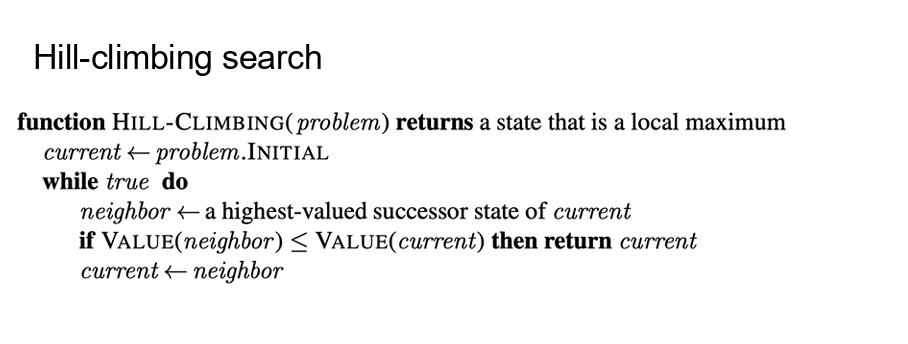

#### Exercise 3: Implement Hill Climbing

Complete the two functions in the cell below.
- `hill_climbing(state)` starts from `state` and returns the state where it gets stuck (a solution or a local optimum).
- `hill_climbing_restarts(n, max_restarts)` calls `hill_climbing` from random states until it finds a solution. It returns the pair `(solution, number_of_attempts)`.

**Steps for `hill_climbing`**
0. Delete the `raise NotImplementedError(...)` lines.
1. Repeat forever:
   - find `best`, the neighbor of `state` with the **fewest conflicts**;
   - if `best` is **not better** than `state` (it has the same number of conflicts or more), stop and return `state`;
   - otherwise move to `best`.

**Steps for `hill_climbing_restarts`**
1. For `i` from 0 to `max_restarts - 1`:
   - run `hill_climbing` from a new random state;
   - if the result has 0 conflicts, return it together with `i + 1`.
2. If no attempt succeeded, return the last state and `max_restarts`.

**Hints**
- `neighbors(state)` returns the list of all the neighbors, `conflicts(state)` counts the attacking pairs, `random_state(n)` creates a random board.
- `min(a_list, key=conflicts)` returns the element of the list with the fewest conflicts.
- Here we **minimize** the conflicts: "better" means "fewer conflicts".

When you are done, test your code with `print(conflicts(hill_climbing(random_state())))` and `print(hill_climbing_restarts())`: a single attempt often gets stuck with 1 or 2 conflicts, while with random restarts you should get a board with 0 conflicts.

In [ ]:
def hill_climbing(state):
    raise NotImplementedError("Complete hill_climbing")   # TODO: delete this line
    while True:
        best = ...      # TODO: the neighbor of state with the fewest conflicts
        # TODO: if best is not better than state, return state
        state = ...     # TODO: move to best


def hill_climbing_restarts(n=8, max_restarts=100):
    raise NotImplementedError("Complete hill_climbing_restarts")   # TODO: delete this line
    for i in range(max_restarts):
        s = ...         # TODO: run hill_climbing from a random state of size n
        # TODO: if s has 0 conflicts, return s, i + 1
    return s, max_restarts

### Simulated annealing
Picks a random neighbor: always accepts it if it is better, otherwise with probability `e^(Δ/T)`. The **temperature** `T` decreases over time, so at first it explores and at the end it behaves like hill climbing.

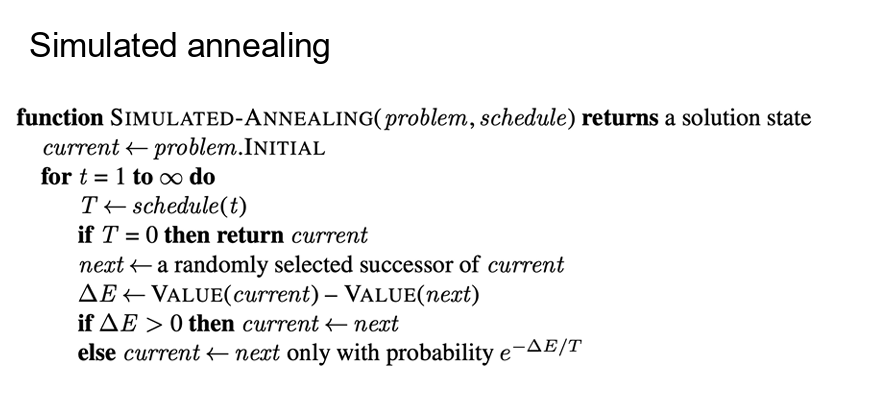

#### Exercise 4: Implement Simulated Annealing

Complete the function in the cell below. `simulated_annealing(state, k, lam, limit)` starts from `state` and returns the final state.

**Steps**
0. Delete the `raise NotImplementedError(...)` line.
1. For each time step `t` from 0 to `limit - 1`:
   - compute the temperature `T = k · e^(−lam · t)` (it starts at `k` and slowly goes down to 0);
   - if `state` has 0 conflicts, or `T` is almost 0 (`T < 1e-6`), return `state`;
   - pick a **random** neighbor `nxt`;
   - compute `delta` = how much `nxt` improves on `state` = `conflicts(state) − conflicts(nxt)` (positive if `nxt` is better);
   - if `delta > 0`, move to `nxt`; otherwise move to `nxt` only **with probability** `e^(delta / T)`.
2. At the end of the loop, return `state`.

**Hints**
- Use `math.exp(x)` for `e^x` and `random.choice(a_list)` to pick a random neighbor.
- `random.random() < p` is `True` with probability `p`: this is how you "accept with probability p".
- When `delta < 0` (a worse move), `e^(delta / T)` is close to 1 if `T` is high and close to 0 if `T` is low: at the beginning the algorithm explores, at the end it only improves.

When you are done, test your code with `plot_queens(simulated_annealing(random_state()))`: the board should have 0 conflicts (or very few).

In [ ]:
def simulated_annealing(state, k=20, lam=0.005, limit=20000):
    raise NotImplementedError("Complete simulated_annealing")   # TODO: delete this line
    for t in range(limit):
        T = ...         # TODO: temperature k * e^(-lam * t)
        # TODO: if state has 0 conflicts or T < 1e-6, return state
        nxt = ...       # TODO: a random neighbor of state
        delta = ...     # TODO: how much nxt improves on state (> 0 if better)
        # TODO: if delta > 0, or with probability e^(delta / T), move to nxt
    return state

# Part 2 — Adversarial search: Tic-Tac-Toe

In this lab we write two AI players for **Tic-Tac-Toe**:
- **Minimax**, which explores the whole game tree and plays perfectly;
- **Monte Carlo Tree Search (MCTS)**, which estimates how good a move is by playing many **random games**, using **UCT** (*Upper Confidence bounds applied to Trees*).

Both players use **the same class** to represent the game, `TicTacToe`. It follows the same idea as the `Problem` class of the search lab: states, actions and a transition model.

**Contents**
1. The game class
2. Minimax
3. Monte Carlo Tree Search (random playouts, UCT)
4. Comparing the players
5. Play against the AI


In [ ]:
# Standard libraries + matplotlib (already available on Colab)
import math, random, re, time
import matplotlib.pyplot as plt

random.seed(0)

## 1. The game class

A **game** is like a search problem, but two players take turns and each one wants to win. A two-player zero-sum game is defined by:
- `initial`: the initial state $s_0$;
- `to_move(s)`: **To-Move(s)**, the player whose turn it is to move in state `s`;
- `actions(s)`: **Actions(s)**, the legal moves in state `s`;
- `result(s, a)`: **Result(s, a)**, the state after move `a` (the **transition model**);
- `is_terminal(s)`: **Is-Terminal(s)**, `True` when the game is over;
- `utility(s, p)`: **Utility(s, p)**, the final value of the terminal state `s` **for player `p`**.

For Tic-Tac-Toe: `utility(s, p)` is `+1` if `p` has won, `-1` if `p` has lost and `0` for a draw.

**State representation**: a tuple of 9 cells read row by row, with `'.'` for an empty cell. Tuples cannot be changed, so `result` always builds a **new** state and never modifies the old one.

```
index:  0 1 2       example:  X . .
        3 4 5                 . O .
        6 7 8                 . . X
```

In [ ]:
class Game:
    "Abstract class: subclasses override the methods below (like Problem in the search lab)."
    def __init__(self, initial):
        self.initial = initial

    def to_move(self, state):          raise NotImplementedError
    def actions(self, state):          raise NotImplementedError
    def result(self, state, action):   raise NotImplementedError
    def is_terminal(self, state):      raise NotImplementedError
    def utility(self, state, player):  raise NotImplementedError


EMPTY = "."
LINES = [(0, 1, 2), (3, 4, 5), (6, 7, 8),     # rows
         (0, 3, 6), (1, 4, 7), (2, 5, 8),     # columns
         (0, 4, 8), (2, 4, 6)]                # diagonals


class TicTacToe(Game):
    def __init__(self):
        super().__init__((EMPTY,) * 9)        # empty board

    def to_move(self, state):
        "X moves first: it is X's turn when X and O have the same number of marks."
        return "X" if state.count("X") == state.count("O") else "O"

    def actions(self, state):
        "List of the empty cells, as (row, col) pairs."
        return [(i // 3, i % 3) for i in range(9) if state[i] == EMPTY]

    def result(self, state, action):
        "New state after the player to move marks the cell action = (row, col)."
        row, col = action
        i = 3 * row + col
        if state[i] != EMPTY:
            raise ValueError(f"Cell {action} is already taken")
        new_state = list(state)
        new_state[i] = self.to_move(state) #X or O
        return tuple(new_state)

    def winner(self, state):
        "X or O if they have three in a row, otherwise None."
        for a, b, c in LINES:
            if state[a] != EMPTY and state[a] == state[b] == state[c]:
                return state[a]
        return None

    def is_terminal(self, state):
        "The game is over when someone has won or the board is full."
        return self.winner(state) is not None or EMPTY not in state

    def utility(self, state, player):
        "+1 if player has won, -1 if player has lost, 0 for a draw."
        w = self.winner(state)
        if w is None:
            return 0
        return 1 if w == player else -1

    def display(self, state):
        for r in range(3):
            print(" ".join(state[3 * r: 3 * r + 3]))
        print()


ttt = TicTacToe()
s = ttt.result(ttt.initial, (1, 1))     # X plays in the centre
s = ttt.result(s, (0, 0))               # O plays in the top-left corner
ttt.display(s)
print("Player to move:", ttt.to_move(s))
print("Legal moves:   ", ttt.actions(s))

To see the board better we draw it with `matplotlib`. If we pass a dictionary `values = {move: number}`, the number is written in the empty cell: we will use it to show how good each move is according to the AI.

In [ ]:
def draw_board(state, title="", values=None):
    "Draw the board; optionally write a value in each empty cell."
    fig, ax = plt.subplots(figsize=(3, 3))
    for k in (1, 2):                                      # grid lines
        ax.plot([k, k], [0, 3], color="black", lw=2)
        ax.plot([0, 3], [k, k], color="black", lw=2)
    for i, mark in enumerate(state):
        r, c = i // 3, i % 3
        x, y = c + 0.5, 2.5 - r                           # row 0 is at the top
        if mark != EMPTY:
            ax.text(x, y, mark, ha="center", va="center", fontsize=36,
                    color="tab:blue" if mark == "X" else "tab:red")
        elif values and (r, c) in values:
            v = values[(r, c)]
            label = f"{v:.2f}" if isinstance(v, float) else str(v)   # scores with 2 decimals, the rest as it is
            ax.text(x, y, label, ha="center", va="center", fontsize=14 if len(label) < 5 else 9, color="gray")
    ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=9)
    plt.show()

draw_board(s, "X in the centre, O in the corner")

### Playing a game

A **player** is simply a function `player(game, state)` that returns a move. This way every AI we write can play against every other one.

`play_game` lets two players play until the game is over and returns the final state.

To play **yourself** against an AI, `play_loop(ai)` runs a simple loop: at each turn it draws the board and asks for your move; then the AI answers. You are X and move first.
- Type your move as two numbers, **row** and **column** from 0 to 2: for example `0 2` is the top-right corner (`0,2` and `(0, 2)` work too).
- Type `q` to stop the game.

In [ ]:
def random_player(game, state):
    "Choose a legal move at random."
    return random.choice(game.actions(state)) #random selection among the empty cells


def play_game(game, x_player, o_player, verbose=False):
    "Play a full game and return the final state."
    players = {"X": x_player, "O": o_player}
    state = game.initial
    while not game.is_terminal(state):
        move = players[game.to_move(state)](game, state)
        if verbose:
            print(game.to_move(state), "plays", move)
        state = game.result(state, move)
    return state


# ---- Human vs AI: one move per cell ----
match = {"game": None, "state": None, "ai": None}

def new_game(ai, game=None):
    "Start a new game: you are X, ai plays O."
    game = game or TicTacToe()
    match.update(game=game, state=game.initial, ai=ai)
    draw_board(match["state"], "New game: your move (you are X)")

def play(row, col=None):
    "Make your move: play(0, 2) or play('0 2'); the AI answers immediately."
    if isinstance(row, str):                                   # also accept play("0 2")
        row, col = map(int, row.replace(",", " ").split())
    game, state = match["game"], match["state"]
    if game is None:
        print("Run new_game(...) first."); return
    if game.is_terminal(state):
        print("The game is over: run new_game(...) to play again."); return
    if (row, col) not in game.actions(state):
        print(f"Invalid move {(row, col)}: choose an empty cell among {game.actions(state)}"); return
    state = game.result(state, (row, col))                    # your move
    ai_move = None
    if not game.is_terminal(state):
        ai_move = match["ai"](game, state)                     # AI move
        state = game.result(state, ai_move)
    match["state"] = state
    if game.is_terminal(state):
        title = f"Game over — winner: {game.winner(state) or 'draw'}"
    else:
        title = f"AI played {ai_move} — your move"
    draw_board(state, title)



# ---- Human vs AI: a simple loop with input() ----
def play_loop(ai, game=None):
    "You are X, ai plays O: type your moves until the game is over (q to quit)."
    game = game or TicTacToe()
    state = game.initial
    draw_board(state, "Your move (you are X)")
    while not game.is_terminal(state):
        text = input("Your move as X: row col (from 0 to 2), or q to quit: ")
        if text.strip().lower() == "q":
            print("Game stopped.")
            return
        try:
            row, col = map(int, re.sub(r"[(),]", " ", text).split())   # accepts 0 2, 0,2, (0, 2)
        except ValueError:
            print("Write two numbers, for example: 0 2")
            continue
        if (row, col) not in game.actions(state):
            print(f"Invalid move {(row, col)}: choose an empty cell among {game.actions(state)}")
            continue
        state = game.result(state, (row, col))                 # your move
        if game.is_terminal(state):
            break
        ai_move = ai(game, state)                               # AI move
        state = game.result(state, ai_move)
        if not game.is_terminal(state):
            draw_board(state, f"AI played {ai_move} — your move")
    draw_board(state, f"Game over — winner: {game.winner(state) or 'draw'}")


final = play_game(ttt, random_player, random_player, verbose=True)
draw_board(final, f"Random vs random — winner: {ttt.winner(final) or 'draw'}")

Now it is your turn: you play X against the random player.

In [ ]:
play_loop(random_player)

## 2. Minimax

Minimax assumes that **both players play optimally**. We call **MAX** the player who is choosing a move (the player to move at the root) and **MIN** the opponent. The **minimax value** of a state is defined inductively:

$$
\text{Minimax}(s) =
\begin{cases}
\text{Utility}(s, \text{MAX}) & \text{if Is-Terminal}(s)\\
\max_{a \in \text{Actions}(s)} \text{Minimax}(\text{Result}(s, a)) & \text{if To-Move}(s) = \text{MAX}\\
\min_{a \in \text{Actions}(s)} \text{Minimax}(\text{Result}(s, a)) & \text{if To-Move}(s) = \text{MIN}
\end{cases}
$$

The **minimax search algorithm** computes it depth-first with two mutually recursive functions:
- `MAX-VALUE(game, state)` returns the pair *(utility, move)* that is best for MAX: it starts from $v = -\infty$ and keeps the move whose `MIN-VALUE` is the **highest**;
- `MIN-VALUE(game, state)` does the same for MIN: it starts from $v = +\infty$ and keeps the move whose `MAX-VALUE` is the **lowest**;
- `MINIMAX-SEARCH(game, state)` saves `player = game.TO-MOVE(state)`, calls `MAX-VALUE` and returns its move.

The utility of a terminal state is always computed for `player`, the MAX player of the root. In Python we pass `player` as an extra parameter to `max_value` and `min_value`.

#### Exercise 5: Implement Minimax

Complete the three functions in the cell below, following the pseudocode seen during the theoretical lecture.

**Steps for `max_value(game, state, player)`**
0. Delete the `raise NotImplementedError(...)` lines.
1. If the state is terminal, return `game.utility(state, player), None`.
2. Set `v = -math.inf` and `move = None`.
3. For each action `a` in `game.actions(state)`:
   - `v2, a2 = min_value(game, game.result(state, a), player)`;
   - if `v2 > v`, update `v, move = v2, a`.
4. Return `v, move`.

**Steps for `min_value(game, state, player)`**: the same, but start from `+math.inf`, call `max_value` and keep the move with `v2 < v`.

**Steps for `minimax_search(game, state)`**
1. `player = game.to_move(state)`.
2. `value, move = max_value(game, state, player)`.
3. Return `move`.

**Hints**
- `math.inf` is $+\infty$ and `-math.inf` is $-\infty$.
- A Python function can return two values: `return v, move`, and you read them with `v2, a2 = ...`.
- `a2` (the move chosen by the opponent) is not used: only its value `v2` matters.

When you are done, test your code with `print(max_value(ttt, ttt.initial, "X"))`: the value should be `0` (with optimal play Tic-Tac-Toe is a draw).

In [ ]:
def minimax_search(game, state):
    raise NotImplementedError("Complete minimax_search")   # TODO: delete this line
    player = ...        # TODO: the player to move (MAX)
    value, move = ...   # TODO: call max_value
    return move


def max_value(game, state, player):
    raise NotImplementedError("Complete max_value")   # TODO: delete this line
    # TODO: if state is terminal, return its utility for player, None
    v, move = ..., None             # TODO: v starts from minus infinity
    for a in game.actions(state):
        v2, a2 = ...                # TODO: min_value of the state after move a
        # TODO: if v2 > v, update v and move
    return v, move


def min_value(game, state, player):
    raise NotImplementedError("Complete min_value")   # TODO: delete this line
    # TODO: if state is terminal, return its utility for player, None
    v, move = ..., None             # TODO: v starts from plus infinity
    for a in game.actions(state):
        v2, a2 = ...                # TODO: max_value of the state after move a
        # TODO: if v2 < v, update v and move
    return v, move

Let's test Minimax on a position where O **must block** X: X has two marks in the top row, so O has to play in the top-right corner `(0, 2)`; any other move loses.

Here O is MAX (it is the player to move). The number in each empty cell is the minimax value **for O** of playing there, that is `min_value` of the state after the move: `0` means a draw, `-1` means that X wins. O chooses the **highest** value.

In [ ]:
t0 = time.time()
print("Minimax value of the empty board for X:", max_value(ttt, ttt.initial, "X")[0], f"({time.time() - t0:.1f} s)")

s = ttt.initial
for move in [(0, 0), (1, 1), (0, 1)]:      # X, O, X
    s = ttt.result(s, move)

values = {a: min_value(ttt, ttt.result(s, a), "O")[0] for a in ttt.actions(s)}
draw_board(s, f"O to move — minimax chooses {minimax_search(ttt, s)}", values)

## 3. Monte Carlo Tree Search

Minimax needs the **whole** game tree, which is impossible for games such as Go, where the branching factor is large and it is difficult to define a good evaluation function. The basic idea of **Monte Carlo Tree Search (MCTS)** is to estimate the value of a state as the **average utility of a number of simulations** of complete games starting at that state.

### 3.1 Playout policy

A **playout** (or *rollout*) simulates a game from a state until the end. The **playout policy** decides which moves to play: here we use **random sampling** (pure Monte Carlo game search), the simplest choice. Better policies use heuristics from human experts or neural networks (as in AlphaGo).

In [ ]:
def random_playout(game, state):
    "Playout policy: play random moves until the game is over; return the winner (X, O or None for a draw)."
    while not game.is_terminal(state):
        state = game.result(state, random.choice(game.actions(state)))
    return game.winner(state)


results = [random_playout(ttt, ttt.initial) for _ in range(1000)]
print("1000 random games from the empty board:",
      {"X wins": results.count("X"), "O wins": results.count("O"), "draws": results.count(None)})

### 3.2 Monte Carlo Tree Search with UCT

MCTS uses an explicit search tree `T` rooted at the current state. Each node `n` of `T` is annotated with `U(n)/N(n)`:
- `U(n)`: the total utility of the simulations through `n`, for the player who **made the move** that leads to `n` (1 for a win, 0.5 for a draw, 0 for a loss);
- `N(n)`: the number of simulations through `n`.

**Selection policy.** It navigates `T` balancing
- **exploitation**: visiting nodes with high historical rewards;
- **exploration**: visiting under-explored nodes with high uncertainty.

A common implementation uses **upper confidence bounds applied to trees (UCT)**: the selection policy chooses the child `n` with the highest value of

$$UCB1(n) = \underbrace{\frac{U(n)}{N(n)}}_{\text{exploitation}} + \underbrace{C \times \sqrt{\frac{\log N(\text{PARENT}(n))}{N(n)}}}_{\text{exploration}}$$

where `PARENT(n)` is the parent node of `n`.
- **Exploitation** `U(n) / N(n)`: the average utility of `n`, high for moves that **won often**.
- **Exploration**: high for moves **tried only a few times** (small `N(n)`) compared to their parent, so no move is ignored forever.
- **`C`** balances the two terms. There is a theoretical argument for $C = \sqrt 2$; in practice `C` is a hyperparameter.

**The algorithm** iterates four steps on `T`:
1. **Selection**: from the root, choose a path guided by the selection policy and UCB1, down to a node that still has unexplored moves (or a terminal node);
2. **Expansion**: generate **one** child of that node;
3. **Simulation**: perform one playout from the new child, guided by the playout policy (the playout is **not** added to `T`);
4. **Back-propagation**: propagate the result of the playout up to the root, updating `U` and `N`.

It stops after a maximum number of iterations or after the allotted time (`IS-TIME-REMAINING`), and returns the move with the **highest number of simulations** `N`.

```
function MONTE-CARLO-TREE-SEARCH(state) returns an action
    tree ← NODE(state)
    while IS-TIME-REMAINING() do
        leaf  ← SELECT(tree)
        child ← EXPAND(leaf)
        result ← SIMULATE(child)
        BACK-PROPAGATE(result, child)
    return the move in ACTIONS(state) whose node has highest number of playouts
```

In [ ]:
class MCTSNode:
    "NODE(state): a node of the search tree T, annotated with U(n)/N(n)."
    def __init__(self, state, parent=None, action=None, untried=()):
        self.state, self.parent, self.action = state, parent, action
        self.children = []
        self.untried = list(untried)   # moves not expanded yet
        self.N = 0                     # N(n): number of simulations through this node
        self.U = 0.0                   # U(n): total utility for the player who moved into this node

    def ucb1(self, C=math.sqrt(2)):
        "UCB1(n) = U(n)/N(n) + C * sqrt(log N(PARENT(n)) / N(n))"
        exploitation = self.U / self.N                                  # average utility: moves that won often
        exploration = C * math.sqrt(math.log(self.parent.N) / self.N)   # high for moves tried only a few times
        return exploitation + exploration

#### Exercise 6: Implement MCTS

The class `MCTSNode` above is already complete. Complete the five functions in the cell below: one for each step of the algorithm, plus the main loop of the pseudocode.

**`select(tree, C)`** — Selection
1. Start from `node = tree` (the root).
2. While the node has **no untried moves** and **has children**, move to the child with the highest `ucb1(C)`.
3. Return the node (the *leaf*).

**`expand(game, leaf)`** — Expansion
1. If the leaf has no untried moves (it is a terminal state), return the leaf itself.
2. Otherwise remove one untried move at random, compute the new state, create the child node (its untried moves are the legal moves of the new state, or an empty list if the new state is terminal), append it to `leaf.children` and return it.

**`simulate(game, child)`** — Simulation: return the winner of a random playout from the state of the child.

**`back_propagate(game, result, child)`** — Back-propagation: go up from the child to the root (`node = node.parent` until it is `None`). For each node add 1 to `N`; if the node has a parent, add to `U` the utility for the player who moved into the node: `1` if `result` is that player, `0.5` for a draw (`result` is `None`).

**`monte_carlo_tree_search(game, state, time_limit, C)`** — the main loop
1. Create the root: `tree = MCTSNode(state, untried=game.actions(state))`.
2. While there is time remaining, run the four steps: `select`, `expand`, `simulate`, `back_propagate`.
3. Return the action of the root child with the highest `N`.

**Hints**
- `node.untried.pop(random.randrange(len(node.untried)))` removes and returns a random move.
- The player who moved into a node is `game.to_move(node.parent.state)`.
- `max(node.children, key=lambda n: n.ucb1(C))` selects the child with the highest UCB1 value; `max(tree.children, key=lambda n: n.N)` the most simulated one.
- `IS-TIME-REMAINING()` becomes `time.time() < end`, with `end = time.time() + time_limit` computed before the loop.

When you are done, test your code with `print(monte_carlo_tree_search(ttt, s))` on the position of section 2: it should print `(0, 2)`.

In [ ]:
def select(tree, C=math.sqrt(2)):
    raise NotImplementedError("Complete select")   # TODO: delete this line
    node = tree
    # TODO: while node has no untried moves and has children, move to the child with the highest ucb1
    return node


def expand(game, leaf):
    raise NotImplementedError("Complete expand")   # TODO: delete this line
    # TODO: if leaf has no untried moves, return leaf
    a = ...             # TODO: remove a random move from leaf.untried
    child_state = ...   # TODO: the state after move a
    untried = ...       # TODO: legal moves of child_state ([] if it is terminal)
    child = MCTSNode(child_state, parent=leaf, action=a, untried=untried)
    # TODO: append child to leaf.children
    return child


def simulate(game, child):
    raise NotImplementedError("Complete simulate")   # TODO: delete this line
    return ...          # TODO: winner of a random playout from child.state


def back_propagate(game, result, child):
    raise NotImplementedError("Complete back_propagate")   # TODO: delete this line
    node = child
    while node is not None:
        # TODO: add 1 to N; if node has a parent, add the utility for the player who moved into node to U
        node = node.parent


def monte_carlo_tree_search(game, state, time_limit=1.0, C=math.sqrt(2)):
    raise NotImplementedError("Complete monte_carlo_tree_search")   # TODO: delete this line
    tree = MCTSNode(state, untried=game.actions(state))
    end = time.time() + time_limit
    while ...:          # TODO: IS-TIME-REMAINING
        leaf = ...      # TODO: SELECT
        child = ...     # TODO: EXPAND
        result = ...    # TODO: SIMULATE
        # TODO: BACK-PROPAGATE
    return ...          # TODO: action of the root child with the highest N

Let's look inside the tree: for the same position we run the four steps for 0.1 seconds and draw, for each move of the root, its `U/N`. Most of the simulations go to the blocking move `(0, 2)`.

In [ ]:
tree = MCTSNode(s, untried=ttt.actions(s))
end = time.time() + 0.1
while time.time() < end:
    child = expand(ttt, select(tree))
    back_propagate(ttt, simulate(ttt, child), child)

values = {n.action: f"{n.U:.0f}/{n.N}" for n in tree.children}
draw_board(s, f"MCTS: U/N of each move\n({tree.N} simulations)", values)

## 4. Comparing the players

Let's make the players play against each other and count wins and draws. To pass a parameter to a player (for example the time MCTS can think for each move) we use a `lambda`.

Remember that Minimax as **X** has to analyse the whole tree at the first move, so those games take a couple of seconds each.

In [ ]:
def tournament(game, x_player, o_player, n_games=20):
    "Play n_games and count the results."
    counts = {"X wins": 0, "O wins": 0, "draws": 0}
    for _ in range(n_games):
        w = game.winner(play_game(game, x_player, o_player))
        counts["X wins" if w == "X" else "O wins" if w == "O" else "draws"] += 1
    return counts


mcts = lambda g, s: monte_carlo_tree_search(g, s, time_limit=0.1)   # 0.1 s per move

matches = [("Minimax (X) vs Random (O)",      minimax_search, random_player,   5),
           ("Random (X) vs Minimax (O)",      random_player,  minimax_search, 20),
           ("MCTS (X) vs Random (O)",         mcts,           random_player,  20),
           ("MCTS (X) vs Minimax (O)",        mcts,           minimax_search, 10),
           ("Minimax (X) vs MCTS (O)",        minimax_search, mcts,            5)]

for name, x, o, n in matches:
    t0 = time.time()
    print(f"{name:<28} {tournament(ttt, x, o, n)}   ({time.time() - t0:.0f} s)")

**What to notice**
- Minimax **never loses**: it is optimal.
- Against a random player, MCTS wins almost every game.
- Against Minimax, MCTS can at best draw: with enough time per move it never loses.

## 5. Play against the AI

Choose your opponent with `AI` and run the cell: as in section 1, at each turn the board is drawn and you type your move as `row col` (for example `0 2`), or `q` to stop. You play **X** and move first.

In [ ]:
AI = minimax_search        # try: minimax_search, mcts, random_player
play_loop(AI)